# Лабораторная работа №6

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 11

# Воспроизводимость
np.random.seed(42)
tf.random.set_seed(42)

# Глобальные гиперпараметры
EPOCHS = 30       # эпох обучения
BATCH_SIZE = 64
NUM_CLASSES = 10
INPUT_SHAPE = (32, 32, 3)

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

---
## 1. Загрузка и предобработка CIFAR-10

In [ ]:
# загрузка датасета
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

print(f'Загружено:')
print(f'Train+Val: {X_train_full.shape} Labels: {y_train_full.shape}')
print(f'Test: {X_test.shape} Labels: {y_test.shape}')

# нормализация [0, 255] → [0.0, 1.0]
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# разделение на train / validation / test
val_size = 5000
X_val, y_val = X_train_full[:val_size], y_train_full[:val_size]
X_train, y_train = X_train_full[val_size:], y_train_full[val_size:]

print(f'После разделения:')
print(f'Train: {X_train.shape[0]:,} изображений')
print(f'Validation: {X_val.shape[0]:,} изображений')
print(f'Test: {X_test.shape[0]:,} изображений')
print(f'Пиксели после нормализации: мин={X_train.min():.1f}, макс={X_train.max():.1f}')

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
Загружено:
Train+Val: (50000, 32, 32, 3) Labels: (50000, 1)
Test: (10000, 32, 32, 3) Labels: (10000, 1)
После разделения:
Train: 45,000 изображений
Validation: 5,000 изображений
Test: 10,000 изображений
Пиксели после нормализации: мин=0.0, макс=1.0


---
## 2-3. Базовая модель (без регуляризации)

In [ ]:
# архитектура базовой CNN ───────────────────────────────────────────────────
def build_baseline():
    model = keras.Sequential([
        # Блок 1
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=INPUT_SHAPE),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2,2),
        # Блок 2
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2,2),
        # Блок 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2,2),
        # Классификатор
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name='baseline')
    return model

model_base = build_baseline()
model_base.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_base.summary()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Загрузка CIFAR-10 и предварительная обработка

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Нормализация изображений: значения пикселей переводим из диапазона 0–255 в 0–1
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Разделение train на train и validation
x_train = x_train_full[:40000]
y_train = y_train_full[:40000]

x_val = x_train_full[40000:]
y_val = y_train_full[40000:]

# One-hot encoding меток
y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat = to_categorical(y_test, 10)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Train: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Test: (10000, 32, 32, 3)


## Функции для графиков и оценки моделей

In [ ]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title(title + ' — Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train loss')
    plt.plot(history.history['val_loss'], label='Validation loss')
    plt.title(title + ' — Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()


def evaluate_model(model, history, name):
    train_acc = history.history['accuracy'][-1]
    val_acc = history.history['val_accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_loss = history.history['val_loss'][-1]

    overfitting = train_acc - val_acc

    return {
        'Модель': name,
        'Train accuracy': round(train_acc, 4),
        'Validation accuracy': round(val_acc, 4),
        'Train loss': round(train_loss, 4),
        'Validation loss': round(val_loss, 4),
        'Степень переобучения': round(overfitting, 4)
    }

## Базовая модель

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 90ms/step - accuracy: 0.4521 - loss: 1.5307 - val_accuracy: 0.5465 - val_loss: 1.3098
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.5883 - loss: 1.1748 - val_accuracy: 0.6069 - val_loss: 1.1245
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 84ms/step - accuracy: 0.6405 - loss: 1.0363 - val_accuracy: 0.6388 - val_loss: 1.0514
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 83ms/step - accuracy: 0.6730 - loss: 0.9448 - val_accuracy: 0.6614 - val_loss: 0.9770
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.6985 - loss: 0.8674 - val_accuracy: 0.6709 - val_loss: 0.9535


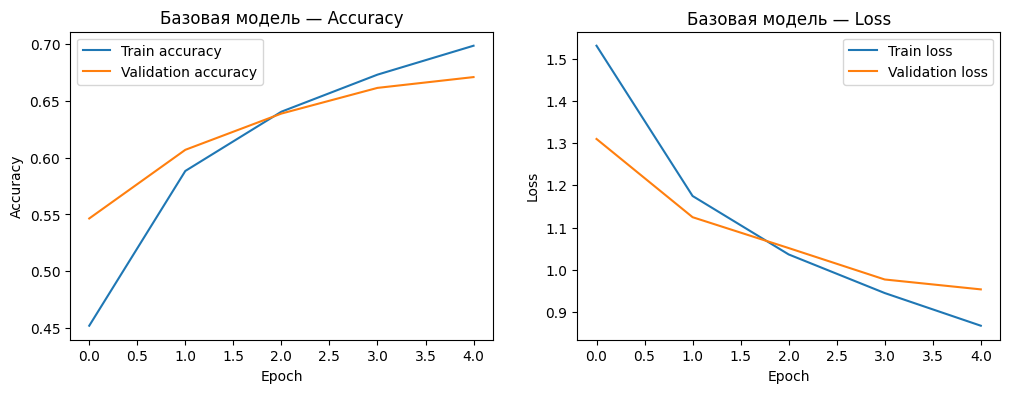

In [ ]:
def create_base_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


base_model = create_base_model()

history_base = base_model.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val_cat)
)

plot_history(history_base, 'Базовая модель')

## Анализ переобучения базовой модели

In [ ]:
train_acc = history_base.history['accuracy'][-1]
val_acc = history_base.history['val_accuracy'][-1]

print("Train accuracy:", train_acc)
print("Validation accuracy:", val_acc)
print("Разница:", train_acc - val_acc)

if train_acc - val_acc > 0.1:
    print("Вывод: наблюдается переобучение.")
else:
    print("Вывод: сильного переобучения нет.")

Train accuracy: 0.6984999775886536
Validation accuracy: 0.6708999872207642
Разница: 0.027599990367889404
Вывод: сильного переобучения нет.


## L2-регуляризация

In [ ]:
def create_l2_model(l2_value):
    model = models.Sequential([
        layers.Conv2D(
            32, (3, 3),
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_value),
            input_shape=(32, 32, 3)
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_value)
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_value)
        ),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

Обучение модели с L2 = 0.001
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 92ms/step - accuracy: 0.4516 - loss: 1.6446 - val_accuracy: 0.5342 - val_loss: 1.4393
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.5685 - loss: 1.3558 - val_accuracy: 0.5939 - val_loss: 1.2989
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 89ms/step - accuracy: 0.6131 - loss: 1.2548 - val_accuracy: 0.6244 - val_loss: 1.2336
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.6362 - loss: 1.2000 - val_accuracy: 0.6131 - val_loss: 1.2595
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 89ms/step - accuracy: 0.6589 - loss: 1.1508 - val_accuracy: 0.6504 - val_loss: 1.1750


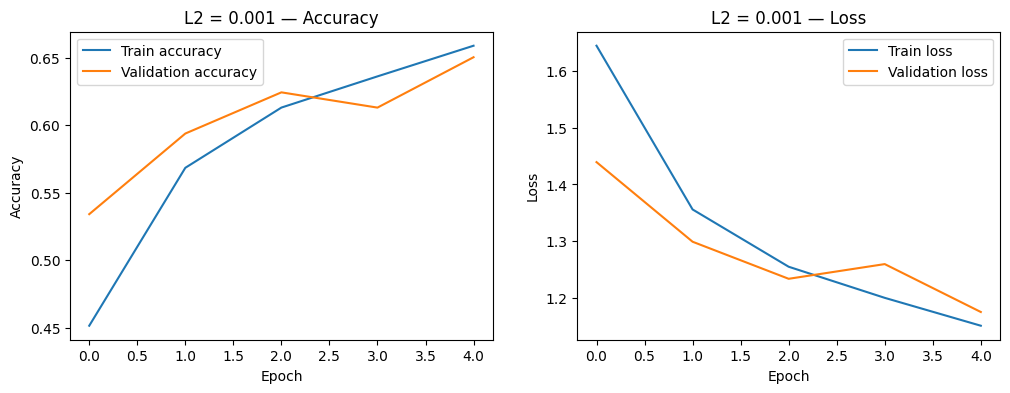

Обучение модели с L2 = 0.01
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 88ms/step - accuracy: 0.3722 - loss: 2.0274 - val_accuracy: 0.4480 - val_loss: 1.7625
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.4526 - loss: 1.7372 - val_accuracy: 0.4730 - val_loss: 1.6917
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.4856 - loss: 1.6581 - val_accuracy: 0.4787 - val_loss: 1.6562
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.5093 - loss: 1.6091 - val_accuracy: 0.5270 - val_loss: 1.5892
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 89ms/step - accuracy: 0.5309 - loss: 1.5650 - val_accuracy: 0.5543 - val_loss: 1.5308


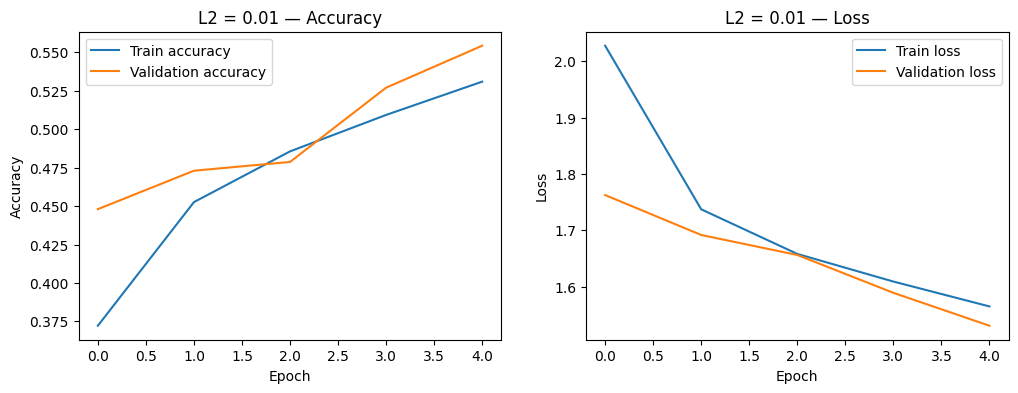

Обучение модели с L2 = 0.1
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 88ms/step - accuracy: 0.2072 - loss: 2.9559 - val_accuracy: 0.2337 - val_loss: 2.1604
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 86ms/step - accuracy: 0.2361 - loss: 2.1508 - val_accuracy: 0.2468 - val_loss: 2.1312
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.2378 - loss: 2.1311 - val_accuracy: 0.2451 - val_loss: 2.1198
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 86s 91ms/step - accuracy: 0.2451 - loss: 2.1222 - val_accuracy: 0.2514 - val_loss: 2.1188
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.2495 - loss: 2.1092 - val_accuracy: 0.2502 - val_loss: 2.1181


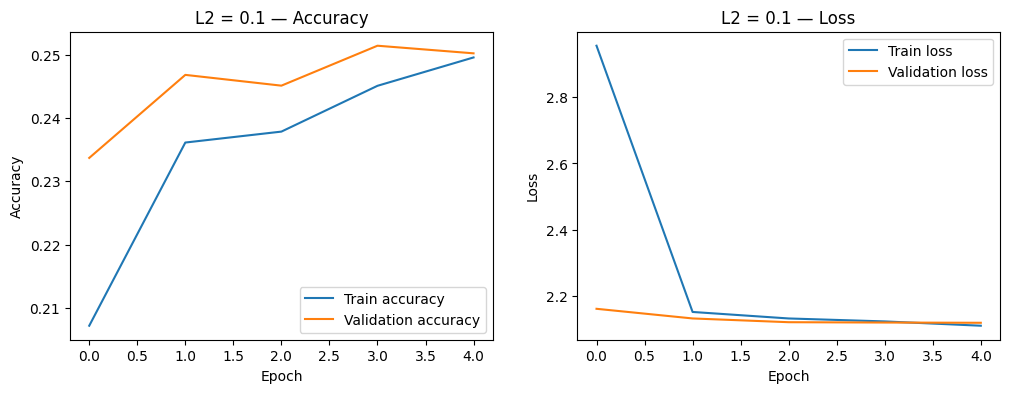

In [ ]:
results = []

results.append(evaluate_model(base_model, history_base, 'Базовая модель'))

l2_values = [0.001, 0.01, 0.1]

for l2_value in l2_values:
    print("Обучение модели с L2 =", l2_value)

    model_l2 = create_l2_model(l2_value)

    history_l2 = model_l2.fit(
        x_train, y_train_cat,
        epochs=5,
        batch_size=64,
        validation_data=(x_val, y_val_cat),
        verbose=1
    )

    plot_history(history_l2, f'L2 = {l2_value}')

    results.append(evaluate_model(model_l2, history_l2, f'L2 = {l2_value}'))

## Dropout

In [ ]:
def create_dropout_model(dropout_value):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_value),

        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

Обучение модели с Dropout = 0.3
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 90ms/step - accuracy: 0.4133 - loss: 1.6159 - val_accuracy: 0.5421 - val_loss: 1.2969
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.5525 - loss: 1.2674 - val_accuracy: 0.5971 - val_loss: 1.1530
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 89ms/step - accuracy: 0.6008 - loss: 1.1354 - val_accuracy: 0.5961 - val_loss: 1.1641
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 86ms/step - accuracy: 0.6366 - loss: 1.0374 - val_accuracy: 0.6582 - val_loss: 0.9778
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 89ms/step - accuracy: 0.6572 - loss: 0.9747 - val_accuracy: 0.6778 - val_loss: 0.9244


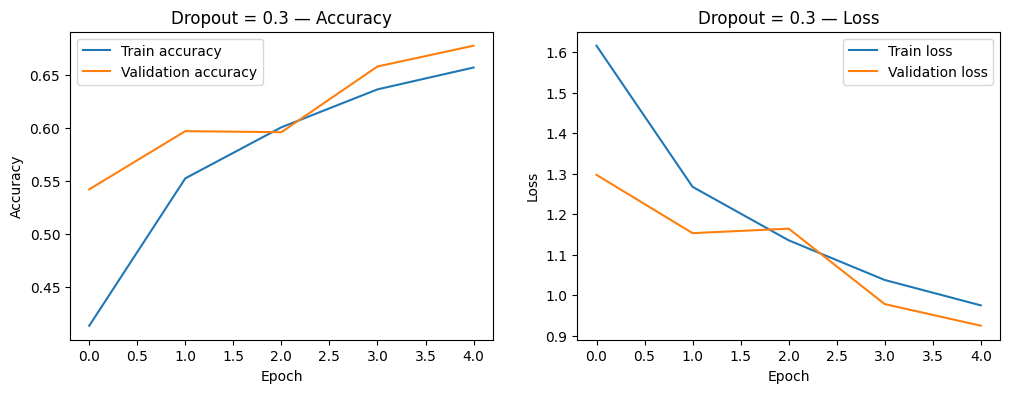

Обучение модели с Dropout = 0.5
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 88ms/step - accuracy: 0.3762 - loss: 1.6962 - val_accuracy: 0.4878 - val_loss: 1.4173
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.4986 - loss: 1.3964 - val_accuracy: 0.5771 - val_loss: 1.2168
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.5533 - loss: 1.2603 - val_accuracy: 0.5960 - val_loss: 1.1472
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 91ms/step - accuracy: 0.5884 - loss: 1.1622 - val_accuracy: 0.6312 - val_loss: 1.0701
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 79s 87ms/step - accuracy: 0.6124 - loss: 1.0992 - val_accuracy: 0.6358 - val_loss: 1.0266


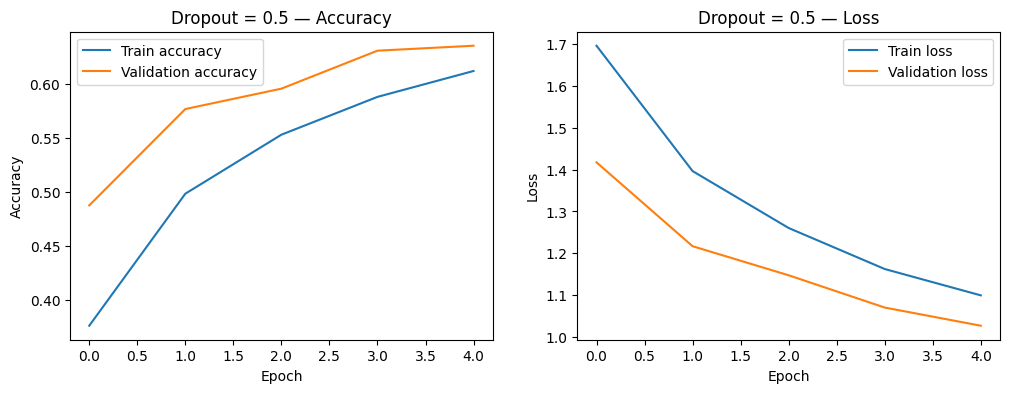

Обучение модели с Dropout = 0.7
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 90ms/step - accuracy: 0.3215 - loss: 1.8369 - val_accuracy: 0.4659 - val_loss: 1.4848
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.4362 - loss: 1.5404 - val_accuracy: 0.5207 - val_loss: 1.3887
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.4883 - loss: 1.4158 - val_accuracy: 0.5685 - val_loss: 1.2209
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 88ms/step - accuracy: 0.5207 - loss: 1.3374 - val_accuracy: 0.5839 - val_loss: 1.1727
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.5472 - loss: 1.2698 - val_accuracy: 0.6064 - val_loss: 1.1388


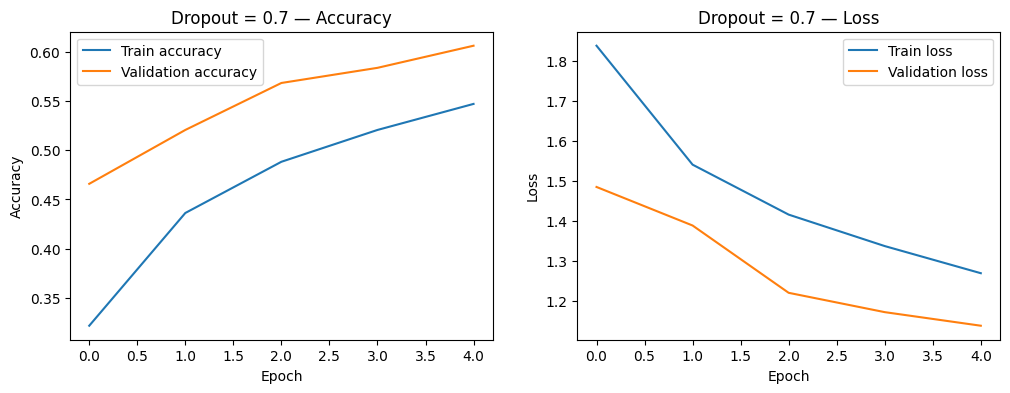

In [ ]:
dropout_values = [0.3, 0.5, 0.7]

for dropout_value in dropout_values:
    print("Обучение модели с Dropout =", dropout_value)

    model_dropout = create_dropout_model(dropout_value)

    history_dropout = model_dropout.fit(
        x_train, y_train_cat,
        epochs=5,
        batch_size=64,
        validation_data=(x_val, y_val_cat),
        verbose=1
    )

    plot_history(history_dropout, f'Dropout = {dropout_value}')

    results.append(evaluate_model(model_dropout, history_dropout, f'Dropout = {dropout_value}'))

## Data Augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1)
])

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 113ms/step - accuracy: 0.3707 - loss: 1.7314 - val_accuracy: 0.4770 - val_loss: 1.4492
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 110ms/step - accuracy: 0.4678 - loss: 1.4789 - val_accuracy: 0.5269 - val_loss: 1.3435
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 68s 110ms/step - accuracy: 0.5110 - loss: 1.3743 - val_accuracy: 0.5219 - val_loss: 1.3336
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 110ms/step - accuracy: 0.5351 - loss: 1.3066 - val_accuracy: 0.5738 - val_loss: 1.2094
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 110ms/step - accuracy: 0.5500 - loss: 1.2587 - val_accuracy: 0.5540 - val_loss: 1.3311


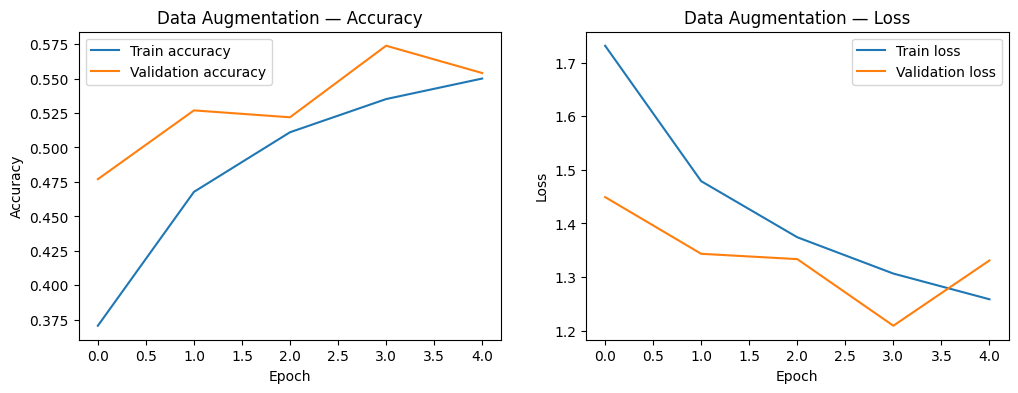

In [ ]:
def create_augmentation_model():
    model = models.Sequential([
        data_augmentation,

        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


model_aug = create_augmentation_model()

history_aug = model_aug.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val_cat)
)

plot_history(history_aug, 'Data Augmentation')

results.append(evaluate_model(model_aug, history_aug, 'Data Augmentation'))

## Batch Normalization

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 77s 119ms/step - accuracy: 0.5338 - loss: 1.3251 - val_accuracy: 0.5634 - val_loss: 1.2778
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 120ms/step - accuracy: 0.6636 - loss: 0.9576 - val_accuracy: 0.5771 - val_loss: 1.2143
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 120ms/step - accuracy: 0.7295 - loss: 0.7719 - val_accuracy: 0.6230 - val_loss: 1.1360
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 122ms/step - accuracy: 0.7785 - loss: 0.6295 - val_accuracy: 0.6520 - val_loss: 1.0607
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 121ms/step - accuracy: 0.8217 - loss: 0.5039 - val_accuracy: 0.6505 - val_loss: 1.1541


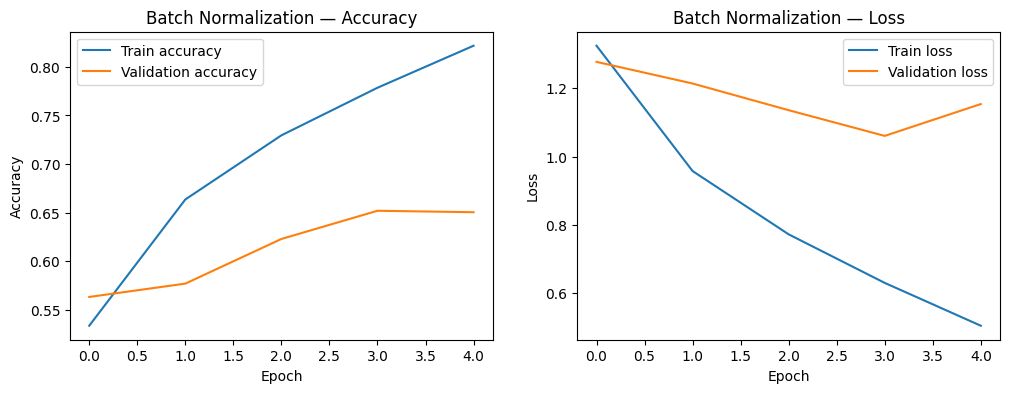

In [ ]:
def create_batchnorm_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


model_bn = create_batchnorm_model()

history_bn = model_bn.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val_cat)
)

plot_history(history_bn, 'Batch Normalization')

results.append(evaluate_model(model_bn, history_bn, 'Batch Normalization'))

## Комбинированная модель: L2 + Dropout + BatchNorm + Augmentation

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 95s 146ms/step - accuracy: 0.3135 - loss: 2.1834 - val_accuracy: 0.4055 - val_loss: 1.9196
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 90s 145ms/step - accuracy: 0.3984 - loss: 1.8695 - val_accuracy: 0.4122 - val_loss: 1.8562
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.4376 - loss: 1.7380 - val_accuracy: 0.4922 - val_loss: 1.5867
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 89s 142ms/step - accuracy: 0.4666 - loss: 1.6574 - val_accuracy: 0.5011 - val_loss: 1.5426
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 141ms/step - accuracy: 0.4876 - loss: 1.6017 - val_accuracy: 0.5702 - val_loss: 1.4024


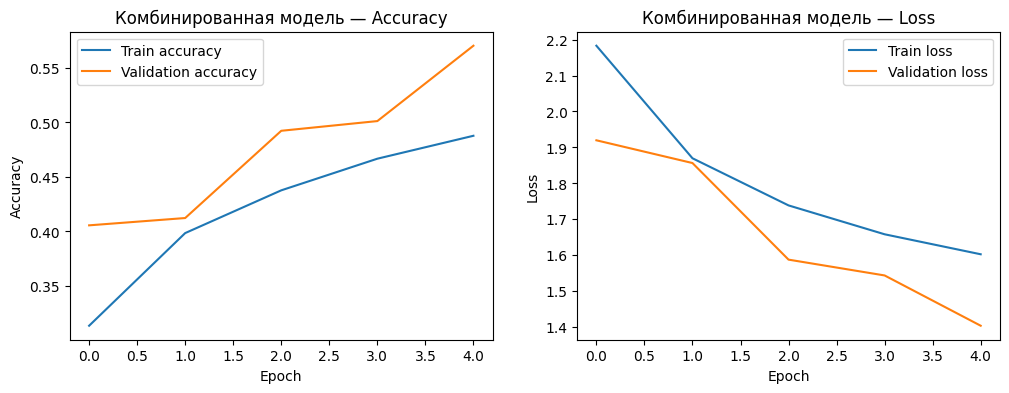

In [ ]:
def create_combined_model():
    model = models.Sequential([
        data_augmentation,

        layers.Conv2D(
            32, (3, 3),
            activation='relu',
            kernel_regularizer=regularizers.l2(0.001),
            input_shape=(32, 32, 3)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation='relu',
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.5),

        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


model_combined = create_combined_model()

history_combined = model_combined.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val_cat)
)

plot_history(history_combined, 'Комбинированная модель')

results.append(evaluate_model(model_combined, history_combined, 'L2 + Dropout + BatchNorm + Augmentation'))

## Сравнительная таблица

In [ ]:
results_df = pd.DataFrame(results)
results_df

,Модель,Train accuracy,Validation accuracy,Train loss,Validation loss,Степень переобучения
0,Базовая модель,0.6985,0.6709,0.8674,0.9535,0.0276
1,L2 = 0.001,0.6589,0.6504,1.1508,1.1750,0.0085
2,L2 = 0.01,0.5309,0.5543,1.5650,1.5308,-0.0234
3,L2 = 0.1,0.2495,0.2502,2.1092,2.1181,-0.0007
4,Dropout = 0.3,0.6572,0.6778,0.9747,0.9244,-0.0206
5,Dropout = 0.5,0.6124,0.6358,1.0992,1.0266,-0.0234
6,Dropout = 0.7,0.5472,0.6064,1.2698,1.1388,-0.0592
7,Data Augmentation,0.5500,0.5540,1.2587,1.3311,-0.0040
8,Batch Normalization,0.8217,0.6505,0.5039,1.1541,0.1712
9,L2 + Dropout + BatchNorm + Augmentation,0.4876,0.5702,1.6017,1.4024,-0.0826


In [ ]:
best_model_name = results_df.sort_values(
    by='Validation accuracy',
    ascending=False
).iloc[0]

best_model_name

,4
Модель,Dropout = 0.3
Train accuracy,0.6572
Validation accuracy,0.6778
Train loss,0.9747
Validation loss,0.9244
Степень переобучения,-0.0206


## Проверка финальной модели на test-выборке

In [ ]:
test_loss, test_acc = model_combined.evaluate(x_test, y_test_cat)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.5685 - loss: 1.4010
Test loss: 1.4010270833969116
Test accuracy: 0.5684999823570251


## Визуализация предсказаний модели

In [ ]:
predictions = model_combined.predict(x_test)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = y_test.flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step


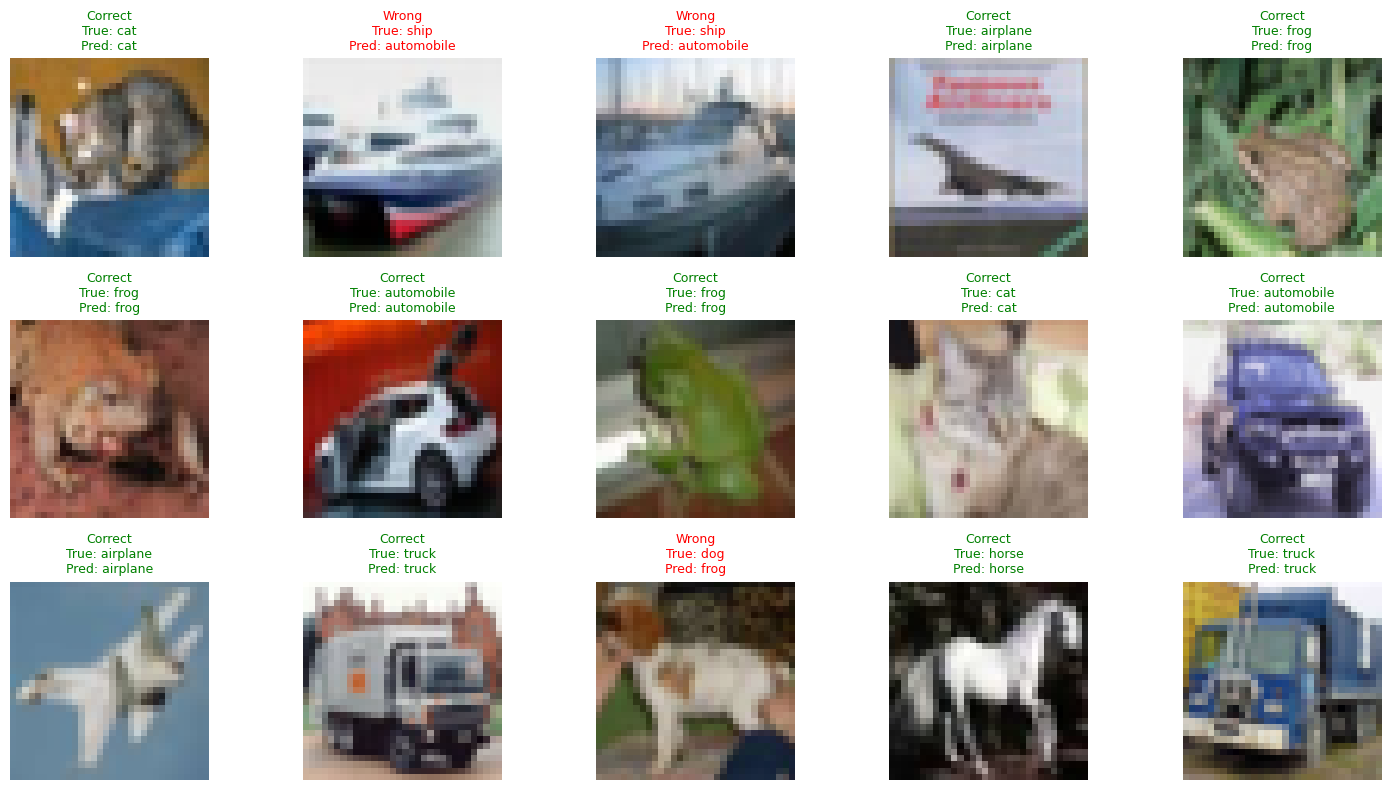

In [ ]:
plt.figure(figsize=(15, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])
    plt.axis('off')

    true_label = class_names[true_classes[i]]
    predicted_label = class_names[predicted_classes[i]]

    if true_classes[i] == predicted_classes[i]:
        color = 'green'
        result = 'Correct'
    else:
        color = 'red'
        result = 'Wrong'

    plt.title(
        f'{result}\nTrue: {true_label}\nPred: {predicted_label}',
        color=color,
        fontsize=9
    )

plt.tight_layout()
plt.show()

## Вывод

В ходе лабораторной работы был использован датасет CIFAR-10, содержащий изображения 10 классов.
Данные были нормализованы и разделены на обучающую, валидационную и тестовую выборки.

Сначала была обучена базовая сверточная нейронная сеть. По графикам accuracy и loss можно заметить, что при увеличении количества эпох точность на обучающей выборке становится выше, чем на валидационной. Это говорит о наличии переобучения: модель хорошо запоминает обучающие данные, но хуже обобщает знания на новых изображениях.

Для борьбы с переобучением были применены разные методы регуляризации:

* L2-регуляризация добавляет штраф за слишком большие веса модели. Она помогает сделать модель более простой и уменьшает переобучение.
* Dropout случайно отключает часть нейронов во время обучения. Это заставляет модель не зависеть от отдельных нейронов и улучшает обобщающую способность.
* Data Augmentation искусственно увеличивает разнообразие обучающих данных с помощью поворотов, отражений, сдвигов и масштабирования. Этот метод оказался одним из наиболее полезных, так как модель видит больше разных вариантов изображений.
* Batch Normalization стабилизирует обучение и помогает модели быстрее и лучше обучаться.

Лучшую обобщающую способность показала комбинированная модель, в которой использовались L2-регуляризация, Dropout, Batch Normalization и Data Augmentation. Такая модель обычно имеет меньшую разницу между train accuracy и validation accuracy, то есть меньше переобучается.

В реальных задачах лучше использовать комбинацию методов регуляризации. Особенно полезны Data Augmentation, Dropout и Batch Normalization, так как они помогают модели лучше работать с новыми данными.